# ¿A qué precio puedo alquilar mi vivienda por noche?
## Predicción del precio de alojamientos de Airbnb en Bogotá

**Integrantes:** Esteban, Rubén, Andrés · **Universidad EIA**, Maestría · **Profesor:** Daniel Orozco Restrepo

**Pregunta de investigación.** Si soy propietario de una vivienda con ciertas características,
¿a qué precio puedo alquilarla por noche?

**Variable a predecir.** El precio por noche en pesos colombianos.

**Tipo de problema.** Regresión, porque el precio es una cantidad continua.

**Datos.** Inside Airbnb, Bogotá, Distrito Capital, Colombia, compilado el 14 de septiembre de
2026. Licencia Creative Commons Attribution 4.0.

---
# Paso 1 — ¿Machine learning?

Quien pregunta es un propietario que todavía no publicó. Tiene una vivienda con unas
características dadas y necesita saber cuánto puede cobrar por noche, porque de eso depende que
el alquiler de corta estancia le convenga frente al arriendo tradicional.

Sin un modelo, lo que haría es mirar cuánto cobran los demás en su barrio. Esa es la **regla a
mano** con que se compara todo lo que sigue: el precio mediano de la localidad.

La regla se queda corta porque el precio no depende solo del barrio. En una misma localidad
conviven habitaciones compartidas y apartamentos para seis personas, cuyo precio difiere varias
veces. Y las características no actúan por separado: la capacidad vale distinto según el tipo de
alojamiento, y la ubicación vale distinto según el tamaño. Esas combinaciones son las que un
promedio por barrio no puede representar y un modelo sí.

In [1]:
import sys                                                   # sys da informacion del interprete en uso
import time                                                  # time mide cuanto tarda cada ajuste
import numpy as np                                           # numpy: operaciones matematicas y arreglos
import pandas as pd                                          # pandas: manejo de tablas
import matplotlib.pyplot as plt                              # matplotlib: graficos
import sklearn                                               # scikit-learn: modelos y preprocesamiento

import airbnb_comun as ac                                    # modulo del proyecto

ac.estilo()                                                  # fija la paleta y el estilo de las figuras
pd.set_option("display.width", 170)                          # ancho de impresion de las tablas
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")  # separador de miles y tres decimales

print("Python       ", sys.version.split()[0])
print("scikit-learn ", sklearn.__version__)
print("Semilla      ", ac.SEMILLA)

Python        3.12.10
scikit-learn  1.9.1
Semilla       42


---
# Paso 2 — Datos

## 2.1 Fuente

Inside Airbnb publica extracciones periódicas de los anuncios visibles en el sitio de Airbnb.
La extracción corresponde a Bogotá, Distrito Capital, Colombia, compilada el 14 de septiembre de
2026, y se distribuye bajo licencia Creative Commons Attribution 4.0, que permite el uso con
atribución de la fuente. La descarga entrega tres archivos comprimidos que se cruzan por el
identificador del alojamiento.

In [2]:
listings = ac.cargar_listings()                              # tabla de alojamientos, con el precio convertido a numero
calendario_cols = pd.read_csv(ac.DATOS / "calendar.csv.gz", nrows=0).columns
resenas_cols = pd.read_csv(ac.DATOS / "reviews.csv.gz", nrows=0).columns

print(f"listings : {listings.shape[0]:>9,} filas  |  una fila por alojamiento publicado")
print(f"calendar : {7119325:>9,} filas  |  una fila por alojamiento y dia del ano siguiente")
print(f"reviews  : {568675:>9,} filas  |  una fila por comentario de un huesped")
print()
print("calendar:", list(calendario_cols))
print("reviews :", list(resenas_cols))

listings :    19,505 filas  |  una fila por alojamiento publicado
calendar : 7,119,325 filas  |  una fila por alojamiento y dia del ano siguiente
reviews  :   568,675 filas  |  una fila por comentario de un huesped

calendar: ['listing_id', 'date', 'available', 'minimum_nights', 'maximum_nights']
reviews : ['listing_id', 'id', 'date', 'reviewer_id', 'reviewer_name', 'comments']


## 2.2 La tabla principal

La unidad de observación es el alojamiento. La tabla de anuncios ya tiene esa granularidad y
aporta las características de la vivienda. El calendario trae una fila por día, y de él se
resume por alojamiento la estancia mínima que el anfitrión exige, que es una decisión suya y no
un resultado de la operación.

Tabla principal: 19,505 filas x 100 columnas
Anuncios que cambian su estancia minima durante el ano: 11.3 %


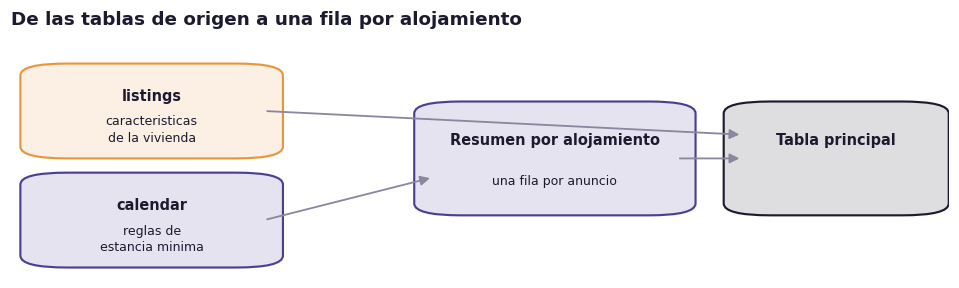

In [24]:
datos = listings.join(ac.reglas_calendario(), on="id")       # resume el calendario a una fila por alojamiento
print(f"Tabla principal: {datos.shape[0]:,} filas x {datos.shape[1]} columnas")
print(f"Anuncios que cambian su estancia minima durante el ano: {datos['varia_estancia_minima'].mean() * 100:.1f} %")

fig, ax = ac.lienzo(11, 2.8)                                 # esquema del cruce
ac.caja(ax, 0.03, 0.52, 0.24, 0.36, "listings", "caracteristicas\nde la vivienda", ac.ACENTO)
ac.caja(ax, 0.03, 0.06, 0.24, 0.36, "calendar", "reglas de\nestancia minima", ac.MORADO)
ac.caja(ax, 0.45, 0.28, 0.26, 0.44, "Resumen por alojamiento", "una fila por anuncio", ac.MORADO)
ac.caja(ax, 0.78, 0.28, 0.20, 0.44, "Tabla principal", "", ac.TINTA)
ac.flecha(ax, (0.27, 0.70), (0.78, 0.60))
ac.flecha(ax, (0.27, 0.24), (0.45, 0.42))
ac.flecha(ax, (0.71, 0.50), (0.78, 0.50))
ax.set_title("De las tablas de origen a una fila por alojamiento", loc="left", pad=10)
plt.show()

## 2.3 La variable a predecir

El precio llega como texto con signo de pesos y separador de miles, y hay que convertirlo a
número antes de cualquier operación.

In [4]:
print("Formato original:  ", listings["price"].dropna().head(3).tolist())
print("Tras la conversion:", listings["precio_noche"].dropna().head(3).round(0).tolist())
print()
print(f"Anuncios con precio publicado: {listings['precio_noche'].notna().sum():,}")
print(f"Anuncios sin precio:           {listings['precio_noche'].isna().sum():,}")
print()
print(listings["precio_noche"].describe(percentiles=[.05, .25, .5, .75, .95]).to_string())

Formato original:   ['$274,830.78', '$71,692.74', '$137,358.40']
Tras la conversion: [274831.0, 71693.0, 137358.0]

Anuncios con precio publicado: 18,794
Anuncios sin precio:           711

count        18,794.000
mean        292,878.340
std       3,849,321.166
min          15,402.260
5%           53,773.330
25%         109,815.875
50%         160,772.000
75%         229,487.750
95%         496,605.600
max     258,514,678.000


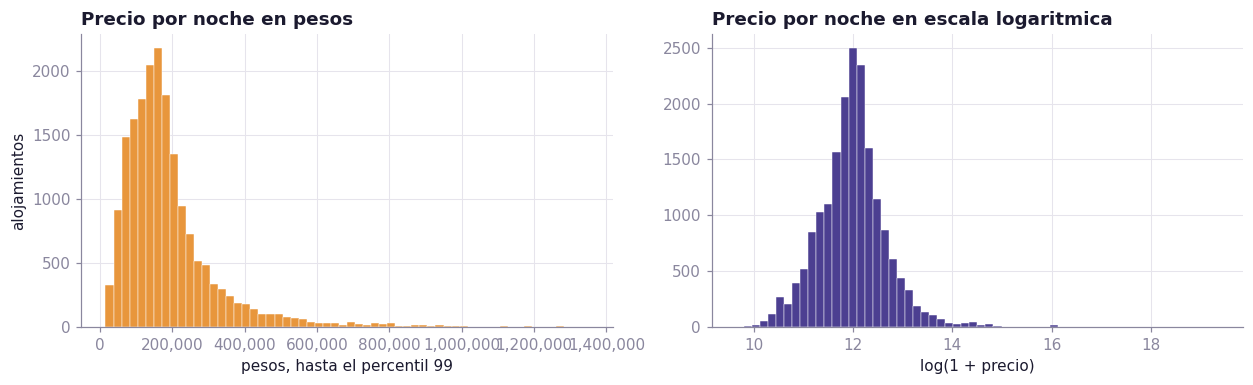

La distribucion es muy asimetrica: la mayoria se concentra en un rango estrecho y una
cola larga se extiende hacia los precios altos. En escala logaritmica queda casi
simetrica, de modo que los modelos se ajustan sobre el logaritmo y devuelven pesos.


In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(11.5, 3.6))          # el precio en las dos escalas

precio = listings["precio_noche"].dropna()
ejes[0].hist(precio[precio <= precio.quantile(0.99)], bins=60, color=ac.ACENTO,
             edgecolor="white", linewidth=0.3)
ejes[0].set_title("Precio por noche en pesos")
ejes[0].set_xlabel("pesos, hasta el percentil 99"); ejes[0].set_ylabel("alojamientos")
ejes[0].xaxis.set_major_formatter(plt.FuncFormatter(ac.miles))

ejes[1].hist(np.log1p(precio), bins=60, color=ac.MORADO, edgecolor="white", linewidth=0.3)
ejes[1].set_title("Precio por noche en escala logaritmica")
ejes[1].set_xlabel("log(1 + precio)")

plt.tight_layout()
plt.show()
print("La distribucion es muy asimetrica: la mayoria se concentra en un rango estrecho y una")
print("cola larga se extiende hacia los precios altos. En escala logaritmica queda casi")
print("simetrica, de modo que los modelos se ajustan sobre el logaritmo y devuelven pesos.")

---
# Paso 3 — Limpieza

## 3.1 Dos regímenes de precio

La fuente no publica un precio de catálogo, sino el resultado de una consulta de
disponibilidad. Para los anuncios con estancia mínima larga esa consulta devuelve un precio
mensual con descuentos ya aplicados, repartido entre las noches del mes, de modo que su precio
por noche corresponde a un producto distinto, más parecido a un arriendo que a un hospedaje.
Esos anuncios salen del análisis.

In [6]:
import json                                                   # json lee el objeto de la cotizacion
ejemplo = listings.loc[listings["es_mensual"]].index[0]
crudo = json.loads(listings.loc[ejemplo, "price_quote_raw"])["quote"]
print("Desglose de la consulta que produjo el precio de un anuncio del regimen mensual:")
for linea in crudo["raw_price_line_items"]:
    print(f"   {linea['description']:32s} {linea['price_string']}")
print(f"   {'precio por noche resultante':32s} ${float(crudo['price_per_night']):,.2f}")
print()

con_precio = datos[datos["precio_noche"].notna()]
regimen = con_precio.groupby("es_mensual").agg(
    anuncios=("id", "size"), precio_mediano=("precio_noche", "median"),
    huespedes_mediana=("accommodates", "median"), estancia_minima=("minimum_nights", "median"))
regimen.index = ["Precio por noche", "Precio mensual prorrateado"]
print(regimen.to_string())
print()
print(f"El regimen mensual cubre el {con_precio['es_mensual'].mean() * 100:.1f} % de los anuncios con precio,")
print("con la misma capacidad mediana y un precio sensiblemente menor.")

datos = datos[datos["precio_noche"].notna() & ~datos["es_mensual"]].copy()
print(f"Alojamientos que continuan: {len(datos):,}")

Desglose de la consulta que produjo el precio de un anuncio del regimen mensual:
   Average monthly price            $9,431,206.00 COP
   Monthly stay discount            -$922,513.20 COP
   Airbnb monthly stay savings      -$263,769.48 COP
   Price after discount             $8,244,923.32 COP
   precio por noche resultante      $274,830.78

                            anuncios  precio_mediano  huespedes_mediana  estancia_minima
Precio por noche               15742     170,000.000              2.000            1.000
Precio mensual prorrateado      3052      96,900.000              2.000           30.000

El regimen mensual cubre el 16.2 % de los anuncios con precio,
con la misma capacidad mediana y un precio sensiblemente menor.
Alojamientos que continuan: 15,742


## 3.2 Duplicados

Un mismo anfitrión publica a menudo varias unidades del mismo edificio, con nombres y precios
distintos. Esos son alojamientos diferentes y se conservan. Lo que sí se descarta es el anuncio
repetido. Un anuncio que coincide con otro del mismo anfitrión en coordenadas, título y
descripción a la vez corresponde al mismo inmueble publicado dos veces.

In [7]:
print(f"Filas identicas en todas las columnas: {datos.duplicated().sum()}")
print(f"Identificadores de alojamiento repetidos: {datos['id'].duplicated().sum()}")
print()
LLAVE_REPETIDO = ["host_id", "latitude", "longitude", "name", "description"]
repetidos = datos.duplicated(subset=LLAVE_REPETIDO, keep="first")
print(f"Anuncios que repiten anfitrion, coordenadas, titulo y descripcion: {repetidos.sum()}")
print(f"Equivalen al {repetidos.mean() * 100:.2f} % de la muestra.")
datos = datos[~repetidos].copy()
print(f"Alojamientos que continuan: {len(datos):,}")

Filas identicas en todas las columnas: 0
Identificadores de alojamiento repetidos: 0

Anuncios que repiten anfitrion, coordenadas, titulo y descripcion: 86
Equivalen al 0.55 % de la muestra.
Alojamientos que continuan: 15,656


## 3.3 Valores extremos

El precio contiene errores de digitación. El criterio de Tukey (1977) sitúa el corte en el
tercer cuartil más tres veces el rango intercuartílico, aplicado sobre el logaritmo del precio
**por huésped**. El precio por huésped compara alojamientos de tamaño distinto: una vivienda
para dieciséis personas sostiene un precio total que en un apartamento para dos sería un error,
de modo que un corte sobre el precio total eliminaría viviendas grandes legítimas.

In [8]:
def por_huesped(tabla):                                       # precio por huesped de una tabla
    return tabla["precio_noche"] / tabla["accommodates"].clip(lower=1)

log_precio = np.log1p(por_huesped(datos))
q1, q3 = log_precio.quantile([0.25, 0.75])
tope = float(np.expm1(q3 + 3 * (q3 - q1)))
extremos = datos[por_huesped(datos) > tope]
print(f"Tope de Tukey sobre el precio por huesped: ${tope:,.0f} por noche")
print(f"Alojamientos por encima del tope: {len(extremos)} ({len(extremos) / len(datos) * 100:.2f} %)")
print()
print(extremos.nlargest(5, "precio_noche")[["precio_noche", "accommodates", "property_type"]].to_string())

Tope de Tukey sobre el precio por huesped: $627,493 por noche
Alojamientos por encima del tope: 103 (0.66 %)

         precio_noche  accommodates                    property_type
4199  258,514,678.000             2        Entire serviced apartment
18499 232,260,501.000             2                    Room in hotel
6696  224,768,226.240             1  Private room in casa particular
1572  160,000,000.000             2             Private room in home
3657  150,025,000.000             3        Entire serviced apartment


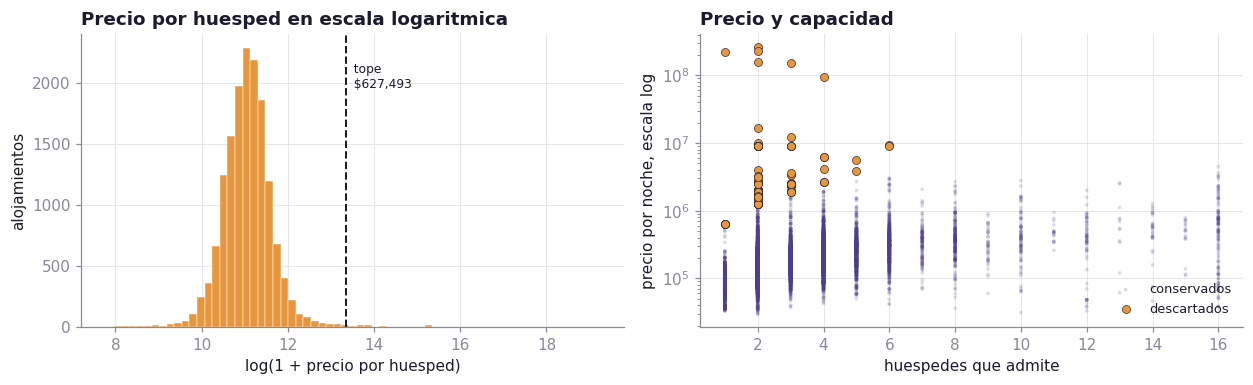

Alojamientos que continuan: 15,553


In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(11.5, 3.6))
ejes[0].hist(log_precio, bins=65, color=ac.ACENTO, edgecolor="white", linewidth=0.3)
ejes[0].axvline(np.log1p(tope), color=ac.TINTA, linewidth=1.3, linestyle="--")
ejes[0].text(np.log1p(tope), ejes[0].get_ylim()[1] * 0.9, f"  tope\n  ${tope:,.0f}",
             fontsize=8, color=ac.TINTA, va="top")
ejes[0].set_title("Precio por huesped en escala logaritmica")
ejes[0].set_xlabel("log(1 + precio por huesped)"); ejes[0].set_ylabel("alojamientos")

ejes[1].scatter(datos["accommodates"], datos["precio_noche"], s=6, alpha=0.18,
                color=ac.MORADO, edgecolors="none", label="conservados")
ejes[1].scatter(extremos["accommodates"], extremos["precio_noche"], s=28, color=ac.ACENTO,
                edgecolors=ac.TINTA, linewidth=0.4, label="descartados")
ejes[1].set_yscale("log"); ejes[1].set_title("Precio y capacidad")
ejes[1].set_xlabel("huespedes que admite"); ejes[1].set_ylabel("precio por noche, escala log")
ejes[1].legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()

datos = datos[por_huesped(datos) <= tope].copy()
print(f"Alojamientos que continuan: {len(datos):,}")

## 3.4 Valores faltantes

La estrategia de relleno se decide comparando el error de cada opción. El procedimiento esconde
el veinte por ciento de los valores conocidos, los reconstruye con cada método y mide el error
absoluto medio contra el valor verdadero.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

usadas = ["accommodates", "bedrooms", "beds", "bathrooms_text", "latitude", "longitude",
          "property_type", "room_type", "neighbourhood_cleansed", "minimum_nights",
          "maximum_nights", "license", "amenities", "name", "description"]
faltantes = datos[usadas].isna().sum()
print("Faltantes entre las columnas que usa el modelo:")
print(faltantes[faltantes > 0].to_string() if (faltantes > 0).any() else "  ninguna")
print()

def comparar_relleno(columna, grupo):                         # compara cuatro formas de rellenar
    conocidos = datos[datos[columna].notna()]
    muestra = conocidos.sample(frac=0.2, random_state=ac.SEMILLA)
    resto = conocidos.drop(muestra.index)
    opciones = {
        "Media": pd.Series(resto[columna].mean(), index=muestra.index),
        "Mediana global": pd.Series(resto[columna].median(), index=muestra.index),
        "Mediana por grupo": muestra[grupo].map(resto.groupby(grupo)[columna].median()).fillna(resto[columna].median()),
    }
    apoyo = ["accommodates", "latitude", "longitude"]
    bosque = RandomForestRegressor(n_estimators=120, random_state=ac.SEMILLA).fit(resto[apoyo], resto[columna])
    opciones["Regresion (bosque)"] = pd.Series(bosque.predict(muestra[apoyo]), index=muestra.index)
    return {n: mean_absolute_error(muestra[columna], v) for n, v in opciones.items()}

relleno = pd.DataFrame({
    "beds (grupo: accommodates)": comparar_relleno("beds", "accommodates"),
    "bedrooms (grupo: accommodates)": comparar_relleno("bedrooms", "accommodates"),
}).T
print(relleno.to_string())
print()
for fila in relleno.index:
    mejor = relleno.loc[fila].idxmin()
    print(f"{fila}: menor error con {mejor.lower()}, MAE {relleno.loc[fila, mejor]:.3f} "
          f"contra {relleno.loc[fila, 'Media']:.3f} de la media")
print()
print("El numero de camas y de habitaciones queda determinado casi por completo por la")
print("capacidad del alojamiento, de modo que condicionar en ella recupera la informacion que")
print("la media ignora. El relleno se aplica dentro del Pipeline, con las medianas aprendidas")
print("en entrenamiento.")

Faltantes entre las columnas que usa el modelo:
bedrooms             6
beds               239
bathrooms_text      28
minimum_nights       7
maximum_nights       7
license           2942
description        204

                                Media  Mediana global  Mediana por grupo  Regresion (bosque)
beds (grupo: accommodates)      0.976           0.942              0.383               0.504
bedrooms (grupo: accommodates)  0.673           0.456              0.311               0.354

beds (grupo: accommodates): menor error con mediana por grupo, MAE 0.383 contra 0.976 de la media
bedrooms (grupo: accommodates): menor error con mediana por grupo, MAE 0.311 contra 0.673 de la media


## 3.5 Fugas

Una fuga es una columna que no estaría disponible en el momento de hacer la predicción. Aquí hay
dos clases, y conviene distinguirlas porque el motivo es distinto.

Las primeras **contienen el precio**. La fuente guarda la cotización que produjo la cifra, y de
ella se puede leer el precio directamente, de modo que un modelo que las usara estaría copiando
la respuesta.

Las segundas **no existen para quien todavía no publicó**. Las calificaciones, el número de
comentarios, la disponibilidad del calendario y el distintivo de superanfitrión solo aparecen
cuando el alojamiento ya recibió huéspedes. Usarlas daría un modelo que no sirve para la
pregunta, porque el propietario que consulta no tiene ninguna de ellas.

In [11]:
cotizacion = ["price_quote_price_per_night", "price_quote_total_price"]
comprueba = datos[datos[cotizacion[0]].notna()]
coincide = np.isclose(comprueba[cotizacion[0]], comprueba["precio_noche"], rtol=0.001).mean() * 100
print(f"La columna de cotizacion por noche coincide con el precio publicado en el {coincide:.1f} % de los casos.")
print()
descartes = ac.tabla_descartes()
print(descartes["Grupo"].value_counts().to_string())
print()
print(f"Columnas fuera del modelo: {len(descartes)}")
print("Tabla completa guardada en", ac.guardar(descartes, "columnas_descartadas.csv").name)

La columna de cotizacion por noche coincide con el precio publicado en el 100.0 % de los casos.

Grupo
Fuga               29
Vacias             14
Redundantes        12
Identificadores     9
Constantes          4
Sin_tratamiento     3

Columnas fuera del modelo: 71
Tabla completa guardada en columnas_descartadas.csv


---
# Paso 4 — Columnas

## 4.1 Qué entra, qué se crea y qué se descarta

Las variables se eligen por el mecanismo que las relaciona con el precio, declarado antes de
medir cualquier asociación. Quedan agrupadas en siete temas, y cada tema corresponde a una
decisión distinta del propietario.

Una parte importante no viene lista en una columna y hay que construirla. El número de baños
está en un texto que dice cosas como un baño privado o baño compartido. Las comodidades llegan
como una lista de texto con miles de elementos distintos. La superficie aparece en la descripción
de algunos anuncios. Y la ubicación entra como distancia en kilómetros a tres puntos de
referencia de la ciudad, además de las coordenadas.

In [26]:
variables = ac.tabla_variables()
print(f"Variables declaradas: {len(variables)} en {variables['Tema'].nunique()} temas")
print()
for tema in variables["Tema"].unique():
    bloque = variables[variables["Tema"] == tema]
    print(f"  {tema:20s} ({len(bloque)})  " + ", ".join(bloque["Variable"]))
print()
distintas = len(set(a for l in datos["amenities"].dropna().apply(json.loads) for a in l))
print(f"Comodidades distintas en el archivo: {distintas:,}")
print("De ellas entran las presentes en al menos uno de cada diez anuncios. Las muy")
print("raras no cambian el error y ensanchan la matriz, y las casi universales no distinguen")
print("a un alojamiento de otro.")
print()
print("Tabla guardada en", ac.guardar(variables, "variables_seleccionadas.csv").name)

Variables declaradas: 31 en 7 temas

  Estructura           (10)  accommodates, bedrooms, beds, n_banos, bano_compartido, huesp_x_habitacion, camas_x_habitacion, banos_x_huesped, metros_cuadrados, declara_area
  Equipamiento         (2)  n_amenities, am_* (dummies)
  Ubicacion            (6)  latitude, longitude, dist_zona_t, dist_aeropuerto, dist_centro_hist, neighbourhood_cleansed
  Reglas de reserva    (3)  log_min_noches, estadia_min_larga, log_max_noches
  Anfitrion            (5)  antiguedad_host, log_anuncios_host, anuncios_completos, es_superhost, tiene_licencia
  Presentacion         (3)  largo_nombre, largo_descripcion, t_* (palabras del titulo)
  Tipologia            (2)  room_type, property_type

Comodidades distintas en el archivo: 3,707
De ellas entran las presentes en al menos uno de cada diez anuncios. Las muy
raras no cambian el error y ensanchan la matriz, y las casi universales no distinguen
a un alojamiento de otro.

Tabla guardada en variables_seleccionadas.csv


## 4.2 Transformaciones y Pipeline

El preprocesamiento es un objeto único que la validación cruzada reajusta en cada partición, de
modo que ninguna mediana ni ninguna lista aprendida con todos los datos viaje a la partición de
validación.

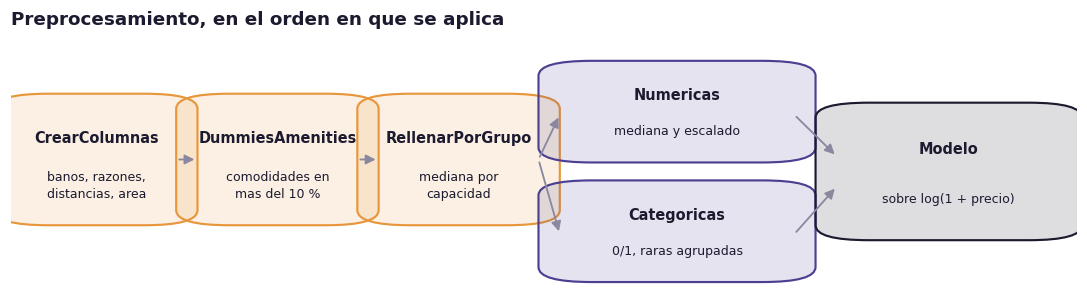

Matriz: 15,553 filas x 126 columnas
  numericas 33 | comodidades 68 | categorias 25
Vacios que quedan: 0

Las 31 variables declaradas se expanden a 126 columnas por dos vias: tres
variables de texto se abren en una columna por categoria, y la lista de comodidades se
abre en una columna de presencia por comodidad frecuente.


In [13]:
fig, ax = ac.lienzo(12.5, 3.0)
ac.caja(ax, 0.005, 0.35, 0.15, 0.40, "CrearColumnas", "banos, razones,\ndistancias, area", ac.ACENTO)
ac.caja(ax, 0.175, 0.35, 0.15, 0.40, "DummiesAmenities", "comodidades en\nmas del 10 %", ac.ACENTO)
ac.caja(ax, 0.345, 0.35, 0.15, 0.40, "RellenarPorGrupo", "mediana por\ncapacidad", ac.ACENTO)
ac.caja(ax, 0.515, 0.56, 0.22, 0.30, "Numericas", "mediana y escalado", ac.MORADO)
ac.caja(ax, 0.515, 0.16, 0.22, 0.30, "Categoricas", "0/1, raras agrupadas", ac.MORADO)
ac.caja(ax, 0.775, 0.30, 0.21, 0.42, "Modelo", "sobre log(1 + precio)", ac.TINTA)
ac.flecha(ax, (0.155, 0.55), (0.175, 0.55)); ac.flecha(ax, (0.325, 0.55), (0.345, 0.55))
ac.flecha(ax, (0.495, 0.55), (0.515, 0.70)); ac.flecha(ax, (0.495, 0.55), (0.515, 0.30))
ac.flecha(ax, (0.735, 0.70), (0.775, 0.56)); ac.flecha(ax, (0.735, 0.30), (0.775, 0.46))
ax.set_ylim(0.1, 0.95)
ax.set_title("Preprocesamiento, en el orden en que se aplica", loc="left", pad=10)
plt.show()

preprocesador = ac.armar_preprocesador(ac.BLOQUES_ELEGIDOS)
matriz = preprocesador.fit_transform(datos, np.log1p(datos["precio_noche"]))
nombres = list(preprocesador.named_steps["columnas"].get_feature_names_out())
print(f"Matriz: {matriz.shape[0]:,} filas x {matriz.shape[1]} columnas")
print(f"  numericas {sum(1 for n in nombres if n.startswith('num__'))}"
      f" | comodidades {sum(1 for n in nombres if n.startswith('am__'))}"
      f" | categorias {sum(1 for n in nombres if n.startswith('cat__'))}")
print(f"Vacios que quedan: {int(np.isnan(matriz).sum())}")
print()
print(f"Las {len(variables)} variables declaradas se expanden a {matriz.shape[1]} columnas por dos vias: tres")
print("variables de texto se abren en una columna por categoria, y la lista de comodidades se")
print("abre en una columna de presencia por comodidad frecuente.")

## 4.3 División en entrenamiento y prueba

Un anfitrión publica a menudo varias unidades del mismo edificio, con precios parecidos. Si esas
unidades quedan repartidas entre las dos partes, el modelo puede recuperar en prueba un precio
que ya vio en entrenamiento, y el error medido dejaría de reflejar la capacidad de predecir un
alojamiento nuevo. La partición agrupa por anfitrión, de modo que ninguno quede dividido.

In [14]:
from sklearn.model_selection import GroupShuffleSplit

tamanos = datos["host_id"].value_counts()
print(f"Anfitriones distintos: {datos['host_id'].nunique():,}")
print(f"Maximo de anuncios de un solo anfitrion: {tamanos.max()}")
print(f"Anuncios de anfitriones con cinco o mas: {datos['host_id'].map(tamanos).ge(5).mean() * 100:.1f} %")

particion = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=ac.SEMILLA)
indices_train, indices_test = next(particion.split(datos, groups=datos["host_id"]))
train = datos.iloc[indices_train].copy()
test = datos.iloc[indices_test].copy()
print()
print(f"Entrenamiento: {len(train):,} anuncios de {train['host_id'].nunique():,} anfitriones")
print(f"Prueba:        {len(test):,} anuncios de {test['host_id'].nunique():,} anfitriones")
print(f"Anfitriones compartidos entre las dos partes: {len(set(train['host_id']) & set(test['host_id']))}")

Anfitriones distintos: 5,880
Maximo de anuncios de un solo anfitrion: 147
Anuncios de anfitriones con cinco o mas: 52.9 %

Entrenamiento: 12,229 anuncios de 4,704 anfitriones
Prueba:        3,324 anuncios de 1,176 anfitriones
Anfitriones compartidos entre las dos partes: 0


---
# Paso 5 — Modelos

Nueve familias comparadas contra la línea base y contra la regla a mano, todas con el mismo
preprocesamiento, la misma partición y la misma validación cruzada de cinco partes agrupada por
anfitrión. Todas se ajustan sobre el logaritmo del precio y devuelven pesos, porque el precio se
mueve de forma proporcional y porque así el modelo no predice valores negativos.

In [15]:
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

cv = GroupKFold(n_splits=5)
METRICAS = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}

def modelo(estimador):                                        # Pipeline completo de un modelo
    base = Pipeline([("prep", ac.armar_preprocesador(ac.BLOQUES_ELEGIDOS)), ("modelo", estimador)])
    return TransformedTargetRegressor(regressor=base, func=np.log1p, inverse_func=np.expm1)

MODELOS = {
    "Regresion lineal": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001, max_iter=5000),
    "KNN (15 vecinos)": KNeighborsRegressor(n_neighbors=15),
    "Arbol (profundidad 8)": DecisionTreeRegressor(max_depth=8, random_state=ac.SEMILLA),
    "Random forest": RandomForestRegressor(n_estimators=300, random_state=ac.SEMILLA, n_jobs=-1),
    "Potenciado (histogramas)": HistGradientBoostingRegressor(random_state=ac.SEMILLA),
    "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.08, max_depth=6, subsample=0.9,
                            colsample_bytree=0.9, random_state=ac.SEMILLA, n_jobs=-1, verbosity=0),
    "Red neuronal (64-32)": MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=400,
                                         random_state=ac.SEMILLA, early_stopping=True),
}

filas = []
candidatos = [("Linea base (mediana de la ciudad)", DummyRegressor(strategy="median")),
              ("Regla a mano (mediana por localidad)", ac.ReglaPorGrupo("neighbourhood_cleansed"))]
candidatos += [(n, modelo(e)) for n, e in MODELOS.items()]
for nombre, estimador in candidatos:
    t0 = time.time()
    r = cross_validate(estimador, train, train["precio_noche"], cv=cv,
                       groups=train["host_id"], scoring=METRICAS)
    filas.append({"Modelo": nombre, "MAE": -r["test_mae"].mean(), "RMSE": -r["test_rmse"].mean(),
                  "R2": r["test_r2"].mean(), "desv R2": r["test_r2"].std(),
                  "Tiempo (s)": time.time() - t0})
    print(f"  {nombre:36s} R2 {filas[-1]['R2']:6.3f}   {filas[-1]['Tiempo (s)']:5.1f} s", flush=True)

comparacion = pd.DataFrame(filas).set_index("Modelo").sort_values("R2", ascending=False)
print()
print(comparacion.round(3).to_string())
ac.guardar(comparacion, "comparacion_modelos.csv")

  Linea base (mediana de la ciudad)    R2 -0.054     0.1 s
  Regla a mano (mediana por localidad) R2 -0.008     0.1 s
  Regresion lineal                     R2  0.325     9.6 s
  Ridge                                R2  0.325     4.9 s
  Lasso                                R2  0.325     5.7 s
  KNN (15 vecinos)                     R2  0.286     5.2 s
  Arbol (profundidad 8)                R2  0.117     5.3 s
  Random forest                        R2  0.388    90.2 s
  Potenciado (histogramas)             R2  0.392     8.5 s
  XGBoost                              R2  0.398    10.3 s
  Red neuronal (64-32)                 R2    nan    26.7 s

                                            MAE        RMSE     R2  desv R2  Tiempo (s)
Modelo                                                                                 
XGBoost                              66,099.339 158,356.820  0.398    0.047      10.308
Potenciado (histogramas)             65,448.199 159,319.913  0.392    0.049       8.50

WindowsPath('C:/Users/USUARIO/Music/ML_Maestria/proyecto-airbnb/notebooks/salidas/comparacion_modelos.csv')

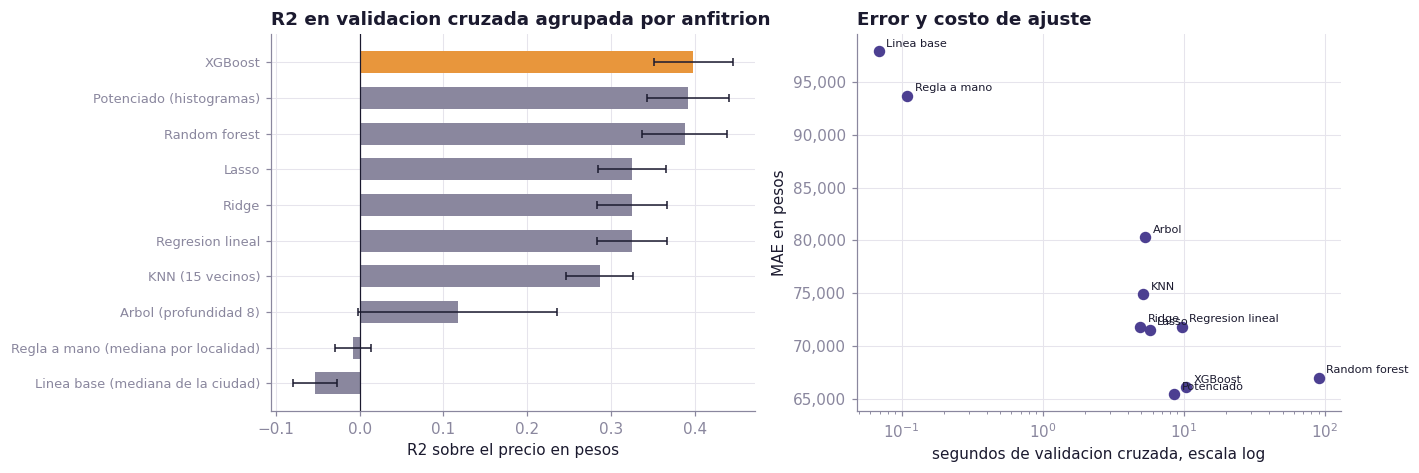

In [16]:
orden = comparacion.sort_values("R2")
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.4))

colores = [ac.ACENTO if n == comparacion["R2"].idxmax() else ac.GRIS for n in orden.index]
ejes[0].barh(orden.index, orden["R2"], color=colores, height=0.62)
ejes[0].errorbar(orden["R2"], np.arange(len(orden)), xerr=orden["desv R2"],
                 fmt="none", ecolor=ac.TINTA, elinewidth=1, capsize=2.5)
ejes[0].axvline(0, color=ac.TINTA, linewidth=0.8)
ejes[0].set_title("R2 en validacion cruzada agrupada por anfitrion")
ejes[0].set_xlabel("R2 sobre el precio en pesos"); ejes[0].tick_params(axis="y", labelsize=8.5)

ejes[1].scatter(comparacion["Tiempo (s)"], comparacion["MAE"], s=42, color=ac.MORADO, zorder=3)
for nombre, fila in comparacion.iterrows():
    ejes[1].annotate(nombre.split(" (")[0], (fila["Tiempo (s)"], fila["MAE"]), fontsize=7.4,
                     xytext=(5, 3), textcoords="offset points", color=ac.TINTA)
ejes[1].set_xscale("log")
ejes[1].set_title("Error y costo de ajuste")
ejes[1].set_xlabel("segundos de validacion cruzada, escala log")
ejes[1].set_ylabel("MAE en pesos")
ejes[1].yaxis.set_major_formatter(plt.FuncFormatter(ac.miles))
plt.tight_layout()
plt.show()

## 5.1 Ajuste de los parámetros del modelo elegido

La búsqueda aleatoria recorre mejor el espacio que una rejilla completa cuando unos pocos
parámetros concentran el efecto, porque no gasta ajustes repitiendo el valor del parámetro que
importa.

In [17]:
from sklearn.model_selection import RandomizedSearchCV

elegido = comparacion.drop(["Linea base (mediana de la ciudad)",
                            "Regla a mano (mediana por localidad)"]).index[0]
REJILLAS = {
    "Random forest": ({"regressor__modelo__n_estimators": [300, 500],
                       "regressor__modelo__max_features": [0.2, 0.4, 0.7, 1.0],
                       "regressor__modelo__min_samples_leaf": [1, 2, 5, 10]},
                      RandomForestRegressor(random_state=ac.SEMILLA, n_jobs=-1)),
    "XGBoost": ({"regressor__modelo__n_estimators": [300, 500, 800],
                 "regressor__modelo__learning_rate": [0.03, 0.05, 0.08],
                 "regressor__modelo__max_depth": [4, 6, 8],
                 "regressor__modelo__subsample": [0.7, 0.9, 1.0]},
                XGBRegressor(random_state=ac.SEMILLA, n_jobs=-1, verbosity=0)),
}
rejilla, estimador_base = REJILLAS.get(elegido, (
    {"regressor__modelo__max_iter": [200, 400, 600],
     "regressor__modelo__learning_rate": [0.03, 0.05, 0.08, 0.12],
     "regressor__modelo__max_leaf_nodes": [15, 31, 63],
     "regressor__modelo__min_samples_leaf": [10, 20, 40]},
    HistGradientBoostingRegressor(random_state=ac.SEMILLA)))

t0 = time.time()
busqueda = RandomizedSearchCV(modelo(estimador_base), rejilla, n_iter=12, cv=GroupKFold(n_splits=3),
                              scoring="r2", random_state=ac.SEMILLA, n_jobs=1)
busqueda.fit(train, train["precio_noche"], groups=train["host_id"])
print(f"Modelo elegido: {elegido}")
print(f"Combinaciones evaluadas: {len(busqueda.cv_results_['params'])} en {time.time() - t0:.0f} s")
print(f"R2 con parametros por defecto: {comparacion.loc[elegido, 'R2']:.3f}")
print(f"R2 con parametros ajustados:   {busqueda.best_score_:.3f}")
print()
for clave, valor in busqueda.best_params_.items():
    print(f"  {clave.split('__')[-1]:20s} {valor}")

Modelo elegido: XGBoost
Combinaciones evaluadas: 12 en 76 s
R2 con parametros por defecto: 0.398
R2 con parametros ajustados:   0.402

  subsample            0.7
  n_estimators         500
  max_depth            6
  learning_rate        0.03


---
# Paso 6 — Evaluación

## 6.1 Medida final sobre la partición de prueba

La partición de prueba se usa una sola vez, con el modelo ya elegido y ajustado.

In [18]:
modelo_final = busqueda.best_estimator_
prediccion = np.clip(modelo_final.predict(test), 0, None)

regla = ac.ReglaPorGrupo("neighbourhood_cleansed").fit(train, train["precio_noche"])
base = DummyRegressor(strategy="median").fit(train, train["precio_noche"])
final = pd.DataFrame({
    "Linea base": ac.metricas(test["precio_noche"], base.predict(test)),
    "Regla a mano": ac.metricas(test["precio_noche"], regla.predict(test)),
    f"{elegido}": ac.metricas(test["precio_noche"], prediccion),
}).T
print(final.to_string())
mejora = (1 - final.loc[elegido, "MAE"] / final.loc["Regla a mano", "MAE"]) * 100
print()
print(f"El modelo reduce el error absoluto medio un {mejora:.1f} % frente a la regla a mano,")
print(f"de ${final.loc['Regla a mano', 'MAE']:,.0f} a ${final.loc[elegido, 'MAE']:,.0f} por noche,")
print(f"sobre un precio mediano observado de ${test['precio_noche'].median():,.0f}.")
ac.guardar(final, "evaluacion_final.csv")

                    MAE      MedAE        RMSE     R2
Linea base   92,234.161 51,974.800 182,818.709 -0.073
Regla a mano 85,888.131 50,437.387 175,673.329  0.010
XGBoost      58,417.449 34,535.321 123,157.731  0.513

El modelo reduce el error absoluto medio un 32.0 % frente a la regla a mano,
de $85,888 a $58,417 por noche,
sobre un precio mediano observado de $175,000.


WindowsPath('C:/Users/USUARIO/Music/ML_Maestria/proyecto-airbnb/notebooks/salidas/evaluacion_final.csv')

## 6.2 Importancia de las variables

La importancia por permutación mide cuánto empeora el error al desordenar una sola columna, de
modo que recoge el aporte de la variable al modelo ya ajustado y no su asociación bruta con el
precio.

bathrooms_text        0.242
accommodates          0.186
bedrooms              0.178
longitude             0.073
latitude              0.057
room_type             0.056
amenities             0.033
property_type         0.021
beds                  0.013
name                  0.011
minimum_nights        0.009
host_listings_count   0.009


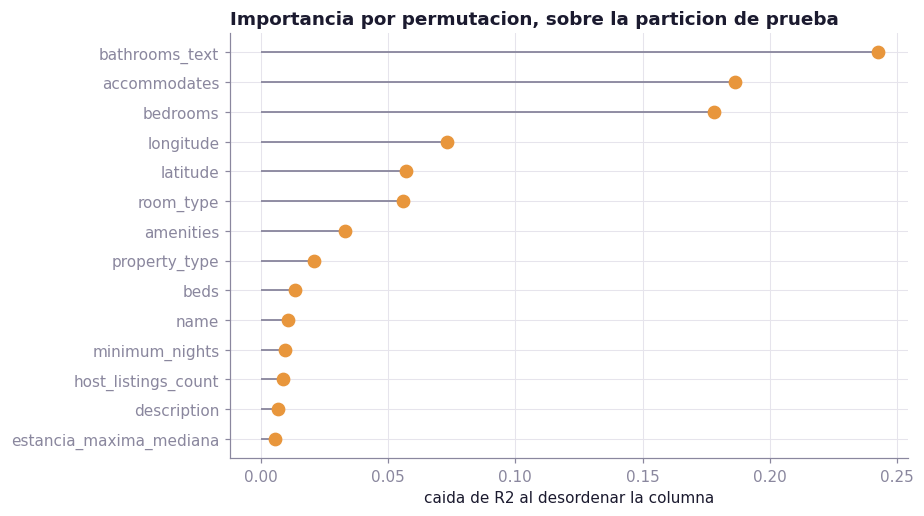

In [19]:
from sklearn.inspection import permutation_importance

muestra = test.sample(min(1200, len(test)), random_state=ac.SEMILLA)
imp = permutation_importance(modelo_final, muestra, muestra["precio_noche"],
                             n_repeats=5, random_state=ac.SEMILLA, scoring="r2")
pesos = pd.Series(imp.importances_mean, index=muestra.columns)
pesos = pesos[pesos > 0].sort_values(ascending=False)
print(pesos.head(12).round(4).to_string())

top = pesos.head(14).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.hlines(top.index, 0, top.values, color=ac.GRIS, linewidth=1.2)
ax.plot(top.values, top.index, "o", color=ac.ACENTO, markersize=8)
ax.set_title("Importancia por permutacion, sobre la particion de prueba")
ax.set_xlabel("caida de R2 al desordenar la columna")
plt.tight_layout()
plt.show()

## 6.3 Dónde se equivoca el modelo

In [20]:
errores = pd.DataFrame({
    "real": test["precio_noche"].to_numpy(), "predicho": prediccion,
    "room_type": test["room_type"].to_numpy(),
    "accommodates": test["accommodates"].to_numpy(),
}, index=test.index)
errores["error_abs"] = (errores["real"] - errores["predicho"]).abs()
errores["error_rel"] = errores["error_abs"] / errores["real"] * 100

print("Error por tipo de alojamiento:")
print(errores.groupby("room_type").agg(
    alojamientos=("real", "size"), precio_mediano=("real", "median"),
    MAE=("error_abs", "mean"), error_relativo=("error_rel", "median")
).sort_values("alojamientos", ascending=False).round(1).to_string())
print()
print("Error por capacidad:")
tramos = pd.cut(errores["accommodates"], [0, 2, 4, 6, 20], labels=["1-2", "3-4", "5-6", "7 o mas"])
print(errores.groupby(tramos, observed=True).agg(
    alojamientos=("real", "size"), precio_mediano=("real", "median"),
    MAE=("error_abs", "mean"), error_relativo=("error_rel", "median")).round(1).to_string())

Error por tipo de alojamiento:
                 alojamientos  precio_mediano        MAE  error_relativo
room_type                                                               
Entire home/apt          2525     191,990.000 63,337.100          18.700
Private room              776     110,000.000 42,751.600          23.600
Shared room                17      59,520.000 52,879.900          86.800
Hotel room                  6     162,000.000 29,850.600          19.200

Error por capacidad:
              alojamientos  precio_mediano         MAE  error_relativo
accommodates                                                          
1-2                   1707     150,000.000  40,356.100          19.200
3-4                   1166     192,750.000  59,806.600          19.700
5-6                    311     300,000.000 113,719.000          23.400
7 o mas                140     389,311.500 144,218.400          20.100


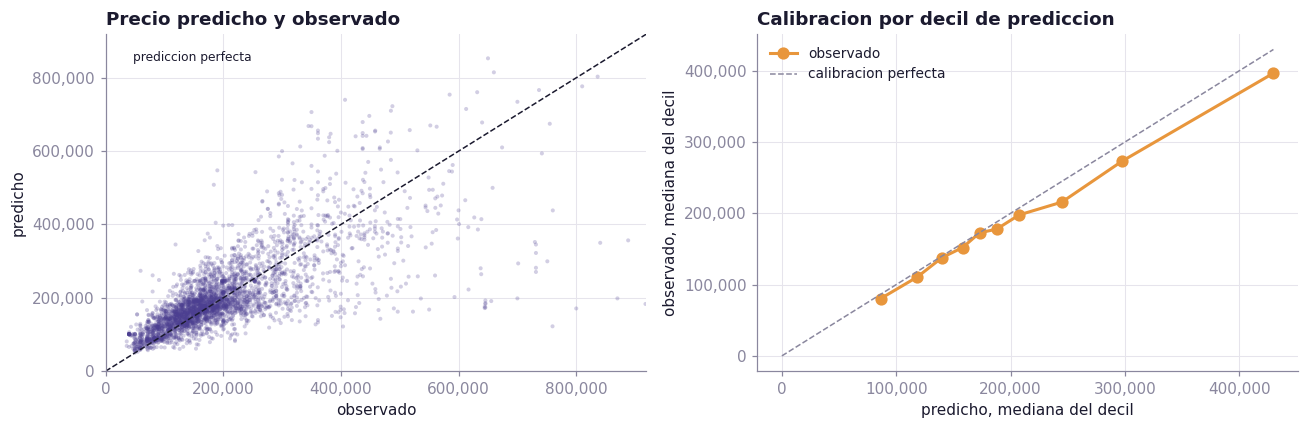

In [21]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
limite = float(np.percentile(errores["real"], 99))
ejes[0].scatter(errores["real"], errores["predicho"], s=7, alpha=0.25, color=ac.MORADO, edgecolors="none")
ejes[0].plot([0, limite], [0, limite], color=ac.TINTA, linewidth=1, linestyle="--")
ejes[0].set_xlim(0, limite); ejes[0].set_ylim(0, limite)
ejes[0].set_title("Precio predicho y observado")
ejes[0].set_xlabel("observado"); ejes[0].set_ylabel("predicho")
ejes[0].xaxis.set_major_formatter(plt.FuncFormatter(ac.miles))
ejes[0].yaxis.set_major_formatter(plt.FuncFormatter(ac.miles))
ejes[0].text(limite * 0.05, limite * 0.92, "prediccion perfecta", fontsize=8, color=ac.TINTA)

decil = pd.qcut(errores["predicho"], 10, labels=False, duplicates="drop")
calib = errores.groupby(decil).agg(observado=("real", "median"), predicho=("predicho", "median"))
ejes[1].plot(calib["predicho"], calib["observado"], "o-", color=ac.ACENTO, linewidth=2, markersize=7, label="observado")
tope_c = calib.max().max()
ejes[1].plot([0, tope_c], [0, tope_c], color=ac.GRIS, linewidth=1, linestyle="--", label="calibracion perfecta")
ejes[1].set_title("Calibracion por decil de prediccion")
ejes[1].set_xlabel("predicho, mediana del decil"); ejes[1].set_ylabel("observado, mediana del decil")
ejes[1].xaxis.set_major_formatter(plt.FuncFormatter(ac.miles))
ejes[1].yaxis.set_major_formatter(plt.FuncFormatter(ac.miles))
ejes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

In [22]:
ejemplos = test.sample(6, random_state=ac.SEMILLA)
posiciones = [test.index.get_loc(i) for i in ejemplos.index]
tabla = pd.DataFrame({
    "tipo": ejemplos["room_type"], "huespedes": ejemplos["accommodates"],
    "habitaciones": ejemplos["bedrooms"], "localidad": ejemplos["neighbourhood_cleansed"],
    "precio real": ejemplos["precio_noche"].round(0),
    "precio predicho": np.round(prediccion[posiciones], 0),
})
tabla["error"] = (tabla["precio predicho"] - tabla["precio real"]).round(0)
print(tabla.to_string())

                  tipo  huespedes  habitaciones       localidad  precio real  precio predicho       error
17443  Entire home/apt          4         3.000            Suba  180,024.000      191,892.000  11,868.000
4189   Entire home/apt          2         1.000            Suba   82,767.000      143,527.000  60,760.000
6984   Entire home/apt          2         1.000       Chapinero  302,813.000      265,313.000 -37,500.000
8476   Entire home/apt          3         1.000        Santa Fe  177,400.000      180,526.000   3,126.000
821    Entire home/apt          3         1.000         Usaquen  207,692.000      233,614.000  25,922.000
7256   Entire home/apt          4         3.000  Barrios Unidos  118,842.000      194,198.000  75,356.000


## 6.4 Respuesta a la pregunta de investigación

In [23]:
print("PREGUNTA. A que precio puede un propietario alquilar su vivienda por noche.")
print("=" * 96)
print()
print(f"Sobre la particion de prueba, con anfitriones que el modelo nunca vio, el precio por")
print(f"noche se predice con un error absoluto medio de ${final.loc[elegido, 'MAE']:,.0f} y una mediana de error")
print(f"de ${final.loc[elegido, 'MedAE']:,.0f}, sobre un precio mediano observado de ${test['precio_noche'].median():,.0f}.")
print()
print(f"El R2 es {final.loc[elegido, 'R2']:.3f}, frente a {final.loc['Regla a mano', 'R2']:.3f} de la regla a mano.")
print(f"La mejora del error frente a mirar el precio tipico del barrio es del {mejora:.1f} %.")
print()
print("Error relativo por tipo de alojamiento:")
for tipo, fila in errores.groupby("room_type").agg(
        n=("real", "size"), rel=("error_rel", "median")).sort_values("n", ascending=False).iterrows():
    print(f"  {tipo:18s} {int(fila['n']):5d} alojamientos   {fila['rel']:5.1f} % de error tipico")
print()
print("Variables de mayor aporte:")
for nombre, valor in pesos.head(6).items():
    print(f"  {nombre:42s} {valor:.4f} de caida de R2")

PREGUNTA. A que precio puede un propietario alquilar su vivienda por noche.

Sobre la particion de prueba, con anfitriones que el modelo nunca vio, el precio por
noche se predice con un error absoluto medio de $58,417 y una mediana de error
de $34,535, sobre un precio mediano observado de $175,000.

El R2 es 0.513, frente a 0.010 de la regla a mano.
La mejora del error frente a mirar el precio tipico del barrio es del 32.0 %.

Error relativo por tipo de alojamiento:
  Entire home/apt     2525 alojamientos    18.7 % de error tipico
  Private room         776 alojamientos    23.6 % de error tipico
  Shared room           17 alojamientos    86.8 % de error tipico
  Hotel room             6 alojamientos    19.2 % de error tipico

Variables de mayor aporte:
  bathrooms_text                             0.2424 de caida de R2
  accommodates                               0.1864 de caida de R2
  bedrooms                                   0.1783 de caida de R2
  longitude                         

# Conclusiones

El precio por noche de un alojamiento en Bogotá se predice a partir de las características que
el propietario conoce antes de publicar, con una mejora amplia sobre mirar el precio típico del
barrio. La capacidad, el tipo de alojamiento y la ubicación concentran la mayor parte de la
capacidad predictiva, y el equipamiento aporta por encima de lo que sugiere su correlación
individual con el precio.

Los modelos de árboles superan a los lineales porque el precio depende de combinaciones de
atributos. La capacidad vale distinto según el tipo de alojamiento, y la ubicación vale distinto
según el tamaño, de modo que un modelo aditivo no representa esas interacciones y uno basado en
particiones sí.

La precisión no es uniforme. Los alojamientos enteros y de capacidad media se predicen mejor que
las habitaciones compartidas y que las viviendas grandes, donde hay pocos casos y el precio
responde a atributos que el archivo no registra.

**Limitaciones.** El precio publicado procede de una consulta de disponibilidad con fecha propia,
de modo que recoge el momento en que se consultó y no una tarifa de catálogo. Los anuncios con
precio mensual prorrateado quedan fuera por corresponder a un producto distinto. Los datos
provienen de una sola extracción, por lo que describen un corte transversal y no permiten
separar la temporada de la anticipación de la reserva. El precio observado es el que el
anfitrión pide, que no es necesariamente el que el mercado paga.